**Part two multi class classification:**

**1. Pre-processing**

In [3]:
#loading and working with data
#first rows , size, data , missing values and duplicates
import pandas as pd
import numpy as np

df = pd.read_csv('predictive_maintenance.csv')
print(df.head())
print(df.shape)
print(df.info())
print(df.isnull().sum())
print("Duplicates:", df.duplicated().sum())

   UDI Product ID Type  Air temperature [K]  Process temperature [K]  \
0    1     M14860    M                298.1                    308.6   
1    2     L47181    L                298.2                    308.7   
2    3     L47182    L                298.1                    308.5   
3    4     L47183    L                298.2                    308.6   
4    5     L47184    L                298.2                    308.7   

   Rotational speed [rpm]  Torque [Nm]  Tool wear [min]  Target Failure Type  
0                    1551         42.8                0       0   No Failure  
1                    1408         46.3                3       0   No Failure  
2                    1498         49.4                5       0   No Failure  
3                    1433         39.5                7       0   No Failure  
4                    1408         40.0                9       0   No Failure  
(10000, 10)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data c

In [4]:
#cleaning the column names to make it more error free -> removing the   [k]
df.columns = (df.columns
              .str.replace(r'\[.*?\]', '', regex=True)   # remove [K], [rpm]...
              .str.strip()
              .str.replace(' ', '_'))
print(df.columns.tolist())

['UDI', 'Product_ID', 'Type', 'Air_temperature', 'Process_temperature', 'Rotational_speed', 'Torque', 'Tool_wear', 'Target', 'Failure_Type']


In [5]:
print(df['Failure_Type'].value_counts())
print(df['Target'].value_counts())

Failure_Type
No Failure                  9652
Heat Dissipation Failure     112
Power Failure                 95
Overstrain Failure            78
Tool Wear Failure             45
Random Failures               18
Name: count, dtype: int64
Target
0    9661
1     339
Name: count, dtype: int64


In [6]:
#the class is imbalaced so the prediction might be wrong -> needs to be fixed

In [7]:
#checking consistency
print(pd.crosstab(df['Target'], df['Failure_Type']))

Failure_Type  Heat Dissipation Failure  No Failure  Overstrain Failure  \
Target                                                                   
0                                    0        9643                   0   
1                                  112           9                  78   

Failure_Type  Power Failure  Random Failures  Tool Wear Failure  
Target                                                           
0                         0               18                  0  
1                        95                0                 45  


In [8]:
#removing contradictory rows
bad = (df['Target'] == 1) & (df['Failure_Type'] == 'No Failure')
print("Contradictory rows removed:", bad.sum())
df = df[~bad].reset_index(drop=True)

Contradictory rows removed: 9


In [9]:
#droping some colums that should not be features  cz the first 2 r useless while the target might cause a data leakage we can't use it as an input
df = df.drop(columns=['UDI', 'Product_ID', 'Target'])

In [10]:
#using the ordinal encoding
df['Type'] = df['Type'].map({'L': 0, 'M': 1, 'H': 2})

In [11]:
#label encoding the target cz  neural network needs numbers and out target has text so we need to encode it
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()
df['label'] = le.fit_transform(df['Failure_Type'])
print(dict(zip(le.classes_, le.transform(le.classes_))))

{'Heat Dissipation Failure': np.int64(0), 'No Failure': np.int64(1), 'Overstrain Failure': np.int64(2), 'Power Failure': np.int64(3), 'Random Failures': np.int64(4), 'Tool Wear Failure': np.int64(5)}


In [12]:
#splitting first
from sklearn.model_selection import train_test_split

feature_cols = ['Type', 'Air_temperature', 'Process_temperature',
                'Rotational_speed', 'Torque', 'Tool_wear']
X = df[feature_cols].values
y = df['label'].values

X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, stratify=y, random_state=42)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, stratify=y_temp, random_state=42)

print(X_train.shape, X_val.shape, X_test.shape)

(6993, 6) (1499, 6) (1499, 6)


In [13]:
#standarize
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)   # learn mean/std on train only
X_val   = scaler.transform(X_val)
X_test  = scaler.transform(X_test)

**2 .Exploratory Data Analysis**

In [14]:
# defining the list once so we use the plot  uses the same features
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid')

num_cols = ['Air_temperature', 'Process_temperature',
            'Rotational_speed', 'Torque', 'Tool_wear']

class_order = ['No Failure', 'Heat Dissipation Failure', 'Power Failure',
               'Overstrain Failure', 'Tool Wear Failure', 'Random Failures']

                          count  percent
Failure_Type                            
No Failure                 9643    96.52
Heat Dissipation Failure    112     1.12
Power Failure                95     0.95
Overstrain Failure           78     0.78
Tool Wear Failure            45     0.45
Random Failures              18     0.18
Imbalance ratio (max/min): 535.7222222222222


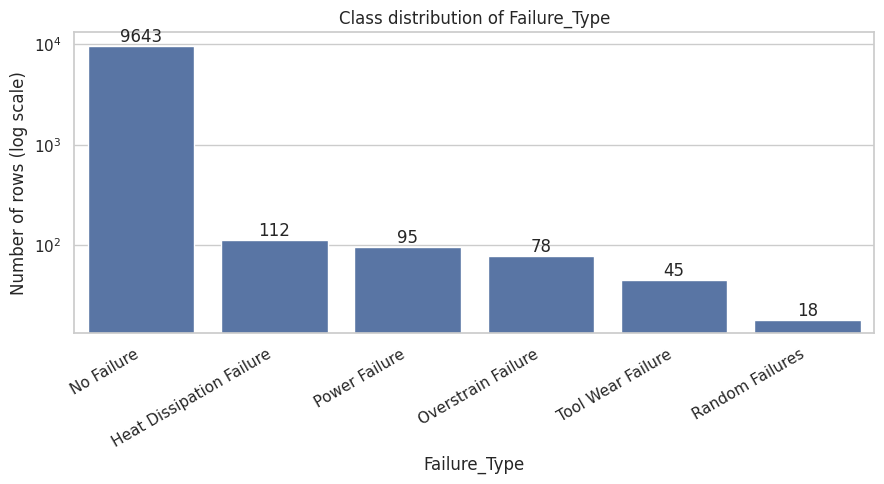

In [15]:
#class distrubution
counts = df['Failure_Type'].value_counts().reindex(class_order)
percent = (counts / counts.sum() * 100).round(2)
print(pd.DataFrame({'count': counts, 'percent': percent}))
print("Imbalance ratio (max/min):", counts.max() / counts.min())

fig, ax = plt.subplots(figsize=(9, 5))
sns.barplot(x=counts.index, y=counts.values, ax=ax)
ax.set_yscale('log')
ax.set_ylabel('Number of rows (log scale)')
ax.set_title('Class distribution of Failure_Type')
plt.xticks(rotation=30, ha='right')
for i, v in enumerate(counts.values):
    ax.text(i, v, str(v), ha='center', va='bottom')
plt.tight_layout()
plt.show()

In [16]:
#statistcs
print(df[num_cols + ['Type']].describe().round(2))
print("\nSkewness:\n", df[num_cols].skew().round(2))

       Air_temperature  Process_temperature  Rotational_speed   Torque  \
count           9991.0              9991.00           9991.00  9991.00   
mean             300.0               310.01           1538.80    39.99   
std                2.0                 1.48            179.32     9.97   
min              295.3               305.70           1168.00     3.80   
25%              298.3               308.80           1423.00    33.20   
50%              300.1               310.10           1503.00    40.10   
75%              301.5               311.10           1612.00    46.70   
max              304.5               313.80           2886.00    76.60   

       Tool_wear     Type  
count    9991.00  9991.00  
mean      107.94     0.50  
std        63.66     0.67  
min         0.00     0.00  
25%        53.00     0.00  
50%       108.00     0.00  
75%       162.00     1.00  
max       253.00     2.00  

Skewness:
 Air_temperature        0.11
Process_temperature    0.02
Rotational_sp

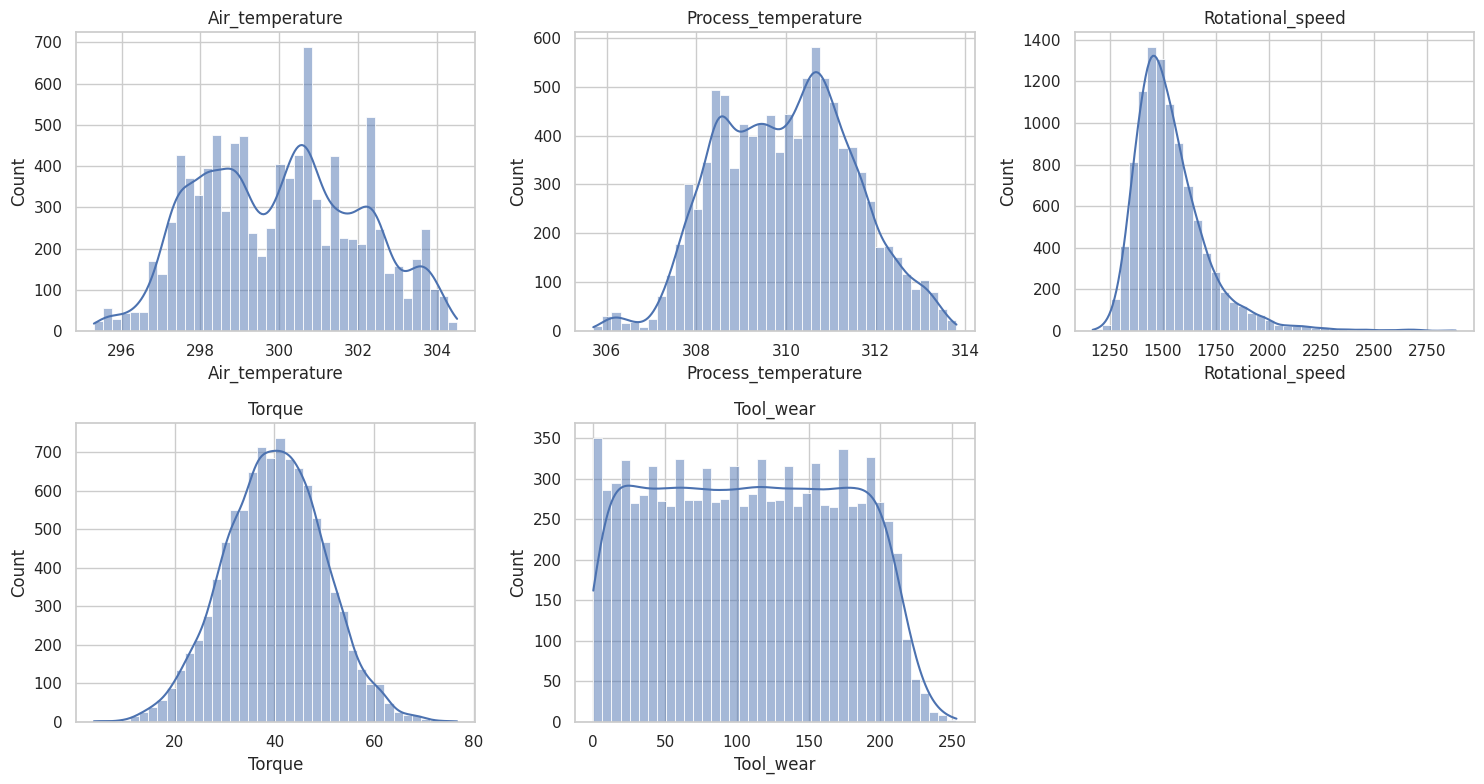

In [17]:
#feature distribution
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.ravel(), num_cols):
    sns.histplot(df[col], bins=40, kde=True, ax=ax)
    ax.set_title(col)
axes.ravel()[-1].axis('off')   # 5 features, 6 slots: hide the empty one
plt.tight_layout()
plt.show()

In [18]:
#outlier check
def iqr_outliers(s):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return ((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum()

print({c: int(iqr_outliers(df[c])) for c in num_cols})

{'Air_temperature': 0, 'Process_temperature': 0, 'Rotational_speed': 418, 'Torque': 70, 'Tool_wear': 0}


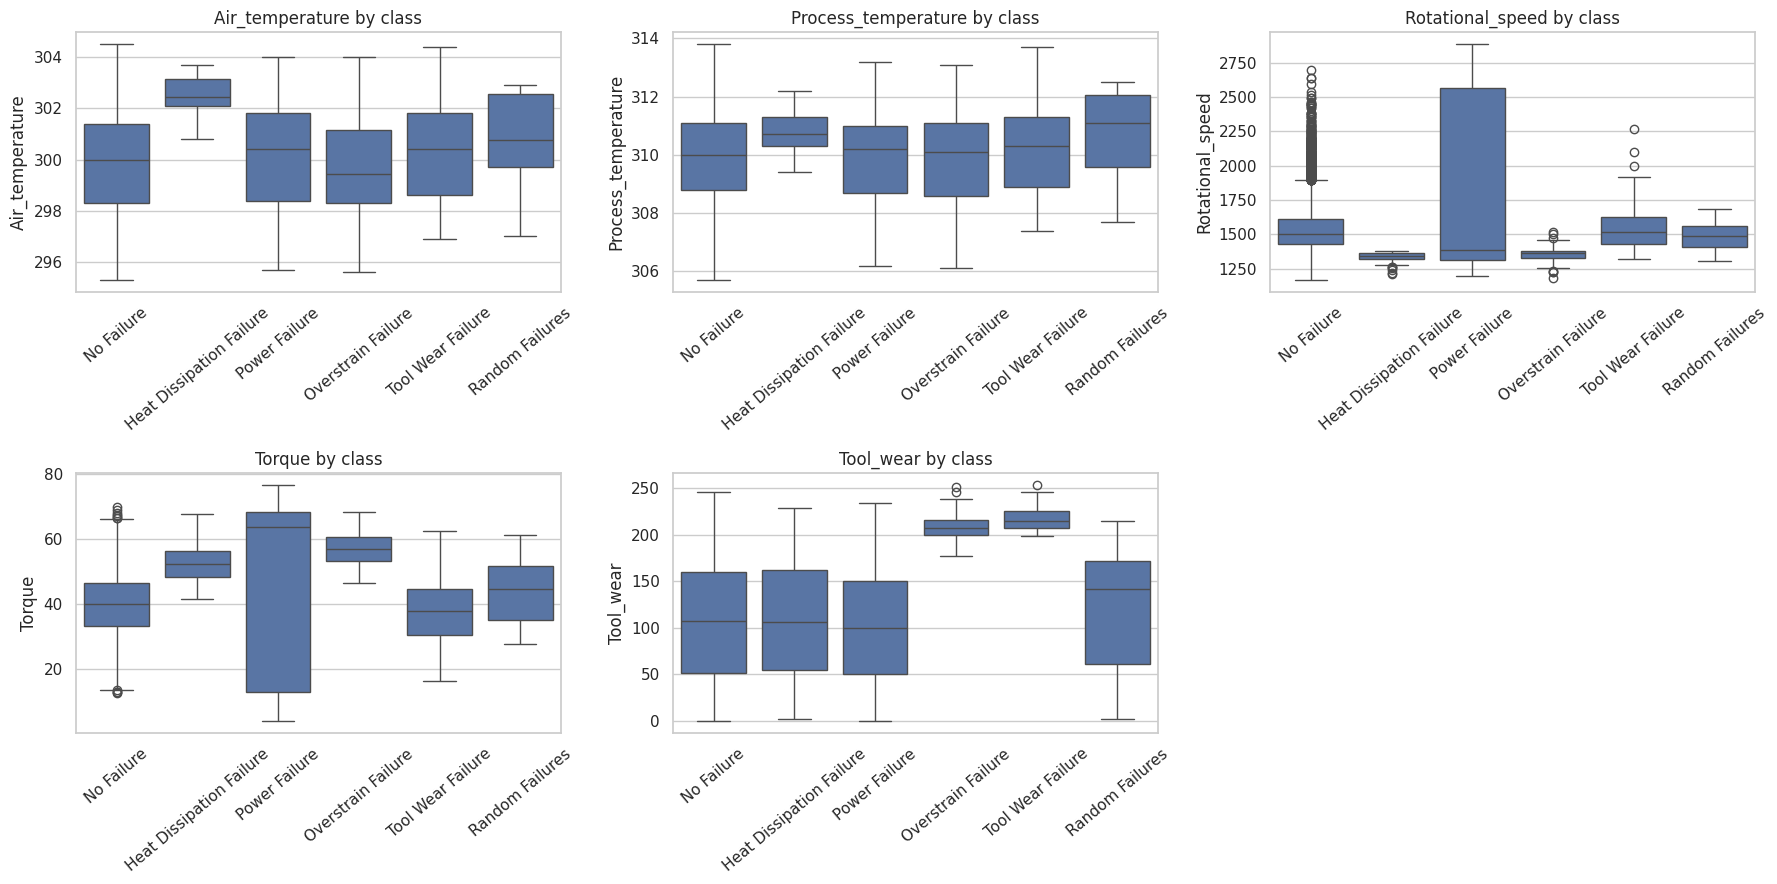

In [19]:
#features vs class
fig, axes = plt.subplots(2, 3, figsize=(18, 9))
for ax, col in zip(axes.ravel(), num_cols):
    sns.boxplot(data=df, x='Failure_Type', y=col, order=class_order, ax=ax)
    ax.set_title(f'{col} by class')
    ax.set_xlabel('')
    ax.tick_params(axis='x', rotation=40)
axes.ravel()[-1].axis('off')
plt.tight_layout()
plt.show()

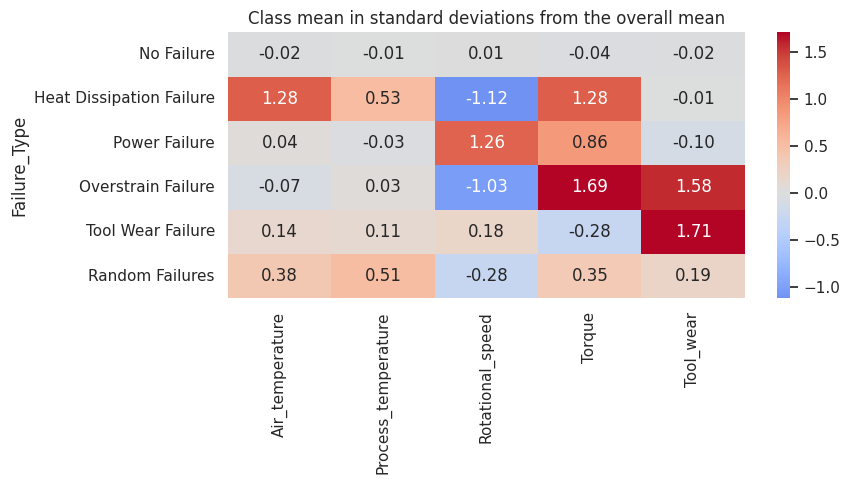

In [20]:
# z-score of each class mean relative to the overall dataset
overall_mean = df[num_cols].mean()
overall_std = df[num_cols].std()
class_means = df.groupby('Failure_Type')[num_cols].mean().reindex(class_order)
zscores = (class_means - overall_mean) / overall_std

plt.figure(figsize=(9, 5))
sns.heatmap(zscores, annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Class mean in standard deviations from the overall mean')
plt.tight_layout()
plt.show()

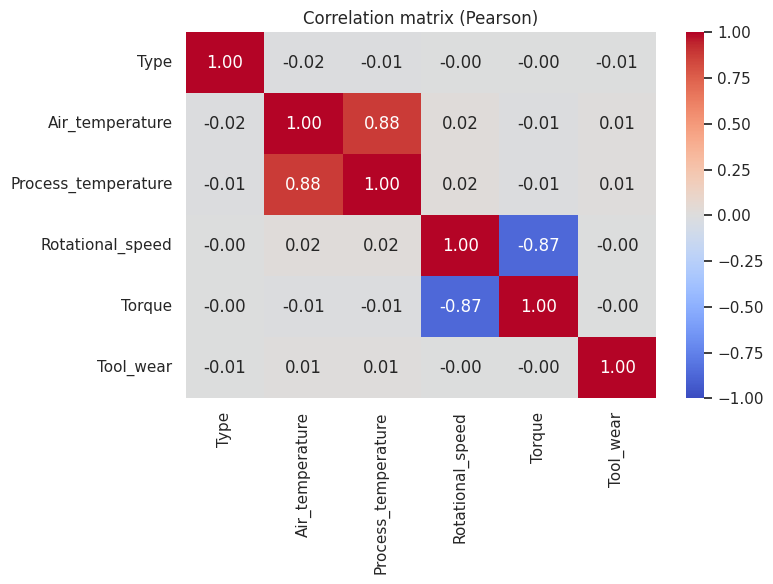

In [21]:
#correclation analysis
corr = df[['Type'] + num_cols].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Correlation matrix (Pearson)')
plt.tight_layout()
plt.show()

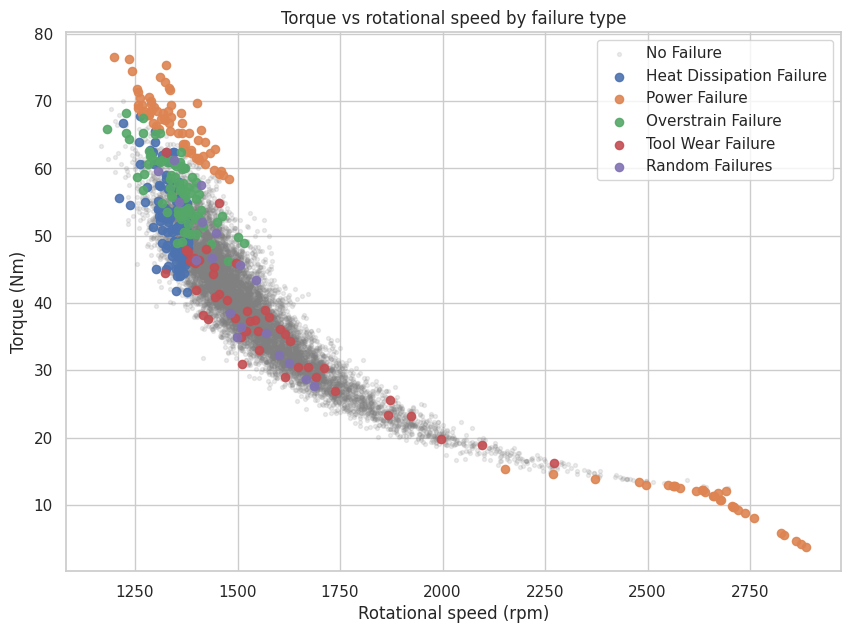

In [22]:
# relationship between the two key sensors
fig, ax = plt.subplots(figsize=(10, 7))
mask_ok = df['Failure_Type'] == 'No Failure'
ax.scatter(df.loc[mask_ok, 'Rotational_speed'], df.loc[mask_ok, 'Torque'],
           s=8, alpha=0.15, color='grey', label='No Failure')
for cls in class_order[1:]:
    m = df['Failure_Type'] == cls
    ax.scatter(df.loc[m, 'Rotational_speed'], df.loc[m, 'Torque'],
               s=35, alpha=0.9, label=cls)
ax.set_xlabel('Rotational speed (rpm)')
ax.set_ylabel('Torque (Nm)')
ax.legend()
ax.set_title('Torque vs rotational speed by failure type')
plt.show()

In [23]:
#Categorical feature Type vs. class
type_names = df['Type'].map({0: 'L', 1: 'M', 2: 'H'})

print("Failure type distribution within each quality level (%):")
print((pd.crosstab(type_names, df['Failure_Type'], normalize='index') * 100)
      .round(2)[class_order])

print("\nQuality level distribution (%):")
print(type_names.value_counts(normalize=True).mul(100).round(1))

Failure type distribution within each quality level (%):
Failure_Type  No Failure  Heat Dissipation Failure  Power Failure  \
Type                                                                
H                  97.60                      0.80           0.50   
L                  95.95                      1.23           0.98   
M                  97.29                      1.00           1.04   

Failure_Type  Overstrain Failure  Tool Wear Failure  Random Failures  
Type                                                                  
H                           0.10               0.60             0.40  
L                           1.22               0.42             0.20  
M                           0.13               0.47             0.07  

Quality level distribution (%):
Type
L    60.0
M    30.0
H    10.0
Name: proportion, dtype: float64


In [24]:
#Verifying  the stratified split
def dist(y_arr):
    return (pd.Series(le.inverse_transform(y_arr))
            .value_counts(normalize=True).mul(100).round(2))

split_check = pd.DataFrame({
    'train': dist(y_train), 'val': dist(y_val), 'test': dist(y_test)
}).reindex(class_order)

counts_check = pd.DataFrame({
    'train': pd.Series(le.inverse_transform(y_train)).value_counts(),
    'val':   pd.Series(le.inverse_transform(y_val)).value_counts(),
    'test':  pd.Series(le.inverse_transform(y_test)).value_counts(),
}).reindex(class_order)

print(split_check)
print(counts_check)

                          train    val   test
No Failure                96.51  96.53  96.53
Heat Dissipation Failure   1.12   1.13   1.13
Power Failure              0.94   1.00   0.93
Overstrain Failure         0.79   0.73   0.80
Tool Wear Failure          0.46   0.47   0.40
Random Failures            0.19   0.13   0.20
                          train   val  test
No Failure                 6749  1447  1447
Heat Dissipation Failure     78    17    17
Power Failure                66    15    14
Overstrain Failure           55    11    12
Tool Wear Failure            32     7     6
Random Failures              13     2     3


**3.Data augmentation (balancing with SMOTE)**

In [25]:
!pip install -U imbalanced-learn

In [26]:
#from imblearn.over_sampling import SMOTENC
from collections import Counter
from imblearn.over_sampling import SMOTENC

def show_counts(y_arr, title):
    s = pd.Series(le.inverse_transform(y_arr)).value_counts().reindex(class_order)
    print(title)
    print(s.to_string(), "\n")

show_counts(y_train, "BEFORE SMOTE (train)")

smote = SMOTENC(
    categorical_features=[0],   # column 0 = Type
    k_neighbors=5,
    random_state=42             # reproducible synthetic samples
)
X_train_res, y_train_res = smote.fit_resample(X_train, y_train)

show_counts(y_train_res, "AFTER SMOTE (train)")
print("Train shape:", X_train.shape, "->", X_train_res.shape)
print("Val  shape :", X_val.shape,  "(untouched)")
print("Test shape :", X_test.shape, "(untouched)")
from imblearn.over_sampling import SMOTENC
from collections import Counter

def show_counts(y_arr, title):
    s = pd.Series(le.inverse_transform(y_arr)).value_counts().reindex(class_order)
    print(title)
    print(s.to_string(), "\n")

show_counts(y_train, "BEFORE SMOTE (train)")

smote = SMOTENC(
    categorical_features=[0],   # column 0 = Type
    k_neighbors=5, # cz each class has more than 5 training rows --> the default
    random_state=42             # reproducible synthetic samples
)
X_train_res, y_train_res = smote.fit_resample(X_train, y_train)# only training

show_counts(y_train_res, "AFTER SMOTE (train)")
print("Train shape:", X_train.shape, "->", X_train_res.shape)
print("Val  shape :", X_val.shape,  "(untouched)")
print("Test shape :", X_test.shape, "(untouched)")

BEFORE SMOTE (train)
No Failure                  6749
Heat Dissipation Failure      78
Power Failure                 66
Overstrain Failure            55
Tool Wear Failure             32
Random Failures               13 

AFTER SMOTE (train)
No Failure                  6749
Heat Dissipation Failure    6749
Power Failure               6749
Overstrain Failure          6749
Tool Wear Failure           6749
Random Failures             6749 

Train shape: (6993, 6) -> (40494, 6)
Val  shape : (1499, 6) (untouched)
Test shape : (1499, 6) (untouched)
BEFORE SMOTE (train)
No Failure                  6749
Heat Dissipation Failure      78
Power Failure                 66
Overstrain Failure            55
Tool Wear Failure             32
Random Failures               13 

AFTER SMOTE (train)
No Failure                  6749
Heat Dissipation Failure    6749
Power Failure               6749
Overstrain Failure          6749
Tool Wear Failure           6749
Random Failures             6749 

Train shape

In [27]:
#Sanity checks
n_real = len(X_train)

# 1) Original rows are preserved, synthetic rows are appended at the end
assert np.allclose(X_train_res[:n_real], X_train)
print("Real rows:", n_real, "| Synthetic rows added:", len(X_train_res) - n_real)

# 2) Type must still only have 3 valid values (back in original units)
X_res_unscaled = scaler.inverse_transform(X_train_res)
print("Unique Type values:", np.unique(X_res_unscaled[:, 0].round(3)))

# 3) No NaNs created
print("NaN count:", np.isnan(X_train_res).sum())

Real rows: 6993 | Synthetic rows added: 33501
Unique Type values: [0. 1. 2.]
NaN count: 0


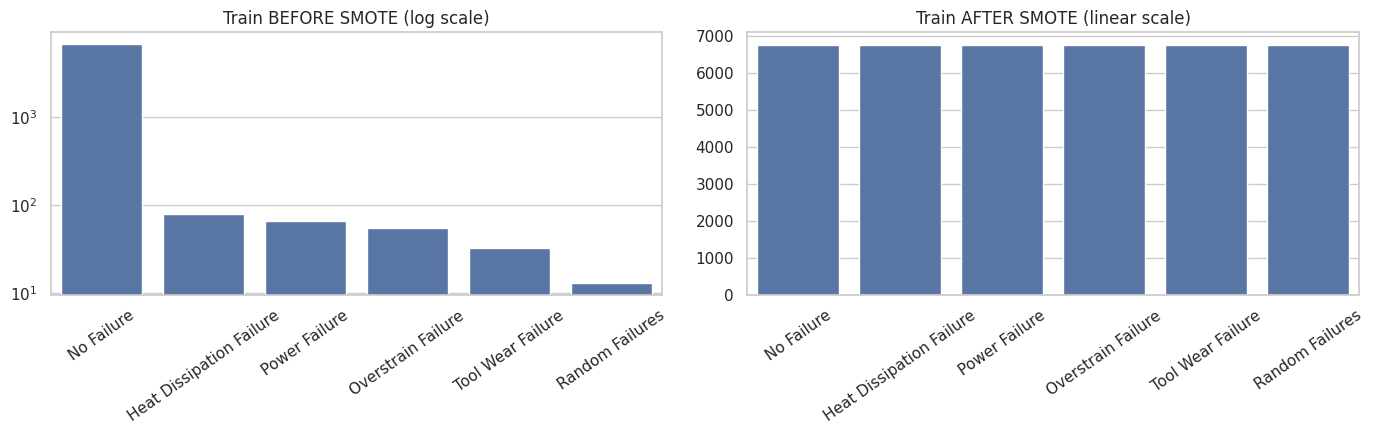

In [28]:
#Visual check
# Before/after class balance
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
before = pd.Series(le.inverse_transform(y_train)).value_counts().reindex(class_order)
after  = pd.Series(le.inverse_transform(y_train_res)).value_counts().reindex(class_order)

sns.barplot(x=before.index, y=before.values, ax=axes[0])
axes[0].set_yscale('log'); axes[0].set_title('Train BEFORE SMOTE (log scale)')
sns.barplot(x=after.index, y=after.values, ax=axes[1])
axes[1].set_title('Train AFTER SMOTE (linear scale)')
for ax in axes:
    ax.tick_params(axis='x', rotation=35)
    ax.set_xlabel('')
plt.tight_layout(); plt.show()

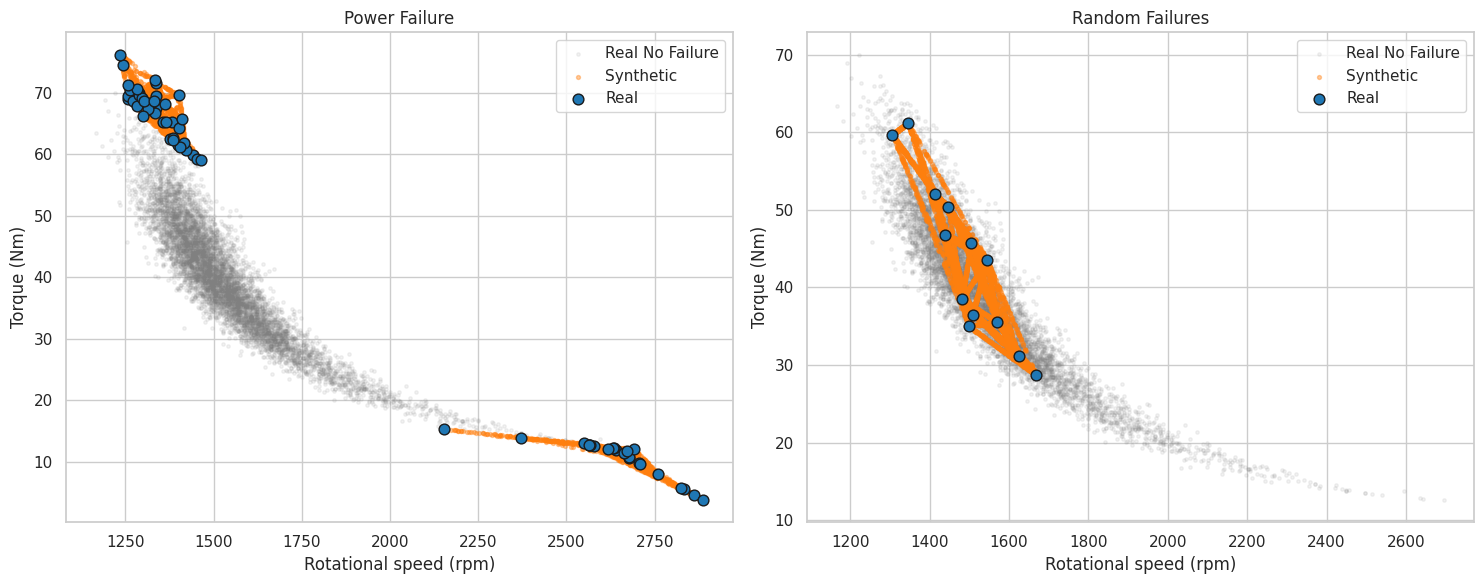

In [29]:
# Are the synthetic points in sensible places?
X_real_unscaled = scaler.inverse_transform(X_train)
is_synth = np.arange(len(X_train_res)) >= n_real
healthy = le.transform(['No Failure'])[0]

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for ax, cls in zip(axes, ['Power Failure', 'Random Failures']):
    c = le.transform([cls])[0]
    # grey background: real healthy machines
    m = y_train == healthy
    ax.scatter(X_real_unscaled[m, 3], X_real_unscaled[m, 4],
               s=6, alpha=0.1, color='grey', label='Real No Failure')
    # synthetic points of this class
    ms = (y_train_res == c) & is_synth
    ax.scatter(X_res_unscaled[ms, 3], X_res_unscaled[ms, 4],
               s=8, alpha=0.4, color='tab:orange', label='Synthetic')
    # real points of this class
    mr = (y_train_res == c) & ~is_synth
    ax.scatter(X_res_unscaled[mr, 3], X_res_unscaled[mr, 4],
               s=60, color='tab:blue', edgecolor='k', label='Real')
    ax.set_title(cls)
    ax.set_xlabel('Rotational speed (rpm)'); ax.set_ylabel('Torque (Nm)')
    ax.legend()
plt.tight_layout(); plt.show()

**4. pytorch classifier**

In [30]:
#we need to fix the seed to make results repeatable
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

torch.manual_seed(42)
np.random.seed(42)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print("Using:", device)

Using: cpu


In [31]:
#tensors and dataloaders
def to_tensors(X, y):
    return (torch.tensor(X, dtype=torch.float32),   # features: float32
            torch.tensor(y, dtype=torch.long))      # class ids: int64

Xtr, ytr = to_tensors(X_train_res, y_train_res)   # balanced (SMOTE) training set
Xva, yva = to_tensors(X_val, y_val)               # real distribution
Xte, yte = to_tensors(X_test, y_test)             # real distribution

train_ds = TensorDataset(Xtr, ytr)

train_loader      = DataLoader(train_ds, batch_size=64, shuffle=True)    # used to learn
train_eval_loader = DataLoader(train_ds, batch_size=1024, shuffle=False) # used to measure
val_loader        = DataLoader(TensorDataset(Xva, yva), batch_size=1024, shuffle=False)
test_loader       = DataLoader(TensorDataset(Xte, yte), batch_size=1024, shuffle=False)

print(Xtr.shape, ytr.shape, "| batches per epoch:", len(train_loader))

torch.Size([40494, 6]) torch.Size([40494]) | batches per epoch: 633


In [32]:
#architecture
class Net(nn.Module):
    def __init__(self, n_in=6, hidden=(64, 32), n_out=6):
        super().__init__()
        layers, prev = [], n_in
        for h in hidden:
            layers += [nn.Linear(prev, h), nn.ReLU()]
            prev = h
        layers.append(nn.Linear(prev, n_out))     # logits, no softmax
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x)

model = Net().to(device)
print(model)
print("Trainable parameters:", sum(p.numel() for p in model.parameters()))

Net(
  (net): Sequential(
    (0): Linear(in_features=6, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=32, bias=True)
    (3): ReLU()
    (4): Linear(in_features=32, out_features=6, bias=True)
  )
)
Trainable parameters: 2726


In [33]:
#evaluation function
def evaluate(model, loader, criterion):
    model.eval()                       # switches off dropout/batchnorm training behavior
    total_loss, correct, n = 0.0, 0, 0
    with torch.no_grad():              # no gradients needed: faster, less memory
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            logits = model(xb)
            total_loss += criterion(logits, yb).item() * len(yb)
            correct    += (logits.argmax(dim=1) == yb).sum().item()
            n          += len(yb)
    return total_loss / n, correct / n

In [50]:
#training loop
# 1) Patched training function
def train_model(model, epochs=50, lr=1e-3, opt_cls=torch.optim.Adam,
                opt_kwargs=None, verbose=True):
    criterion = nn.CrossEntropyLoss()
    optimizer = opt_cls(model.parameters(), lr=lr, **(opt_kwargs or {}))
    hist = {k: [] for k in ['train_loss', 'train_acc',
                            'val_loss', 'val_acc',
                            'test_loss', 'test_acc']}

    for epoch in range(1, epochs + 1):
        # ---- learning phase ----
        model.train()
        for xb, yb in train_loader:          # uses the global train_loader
            xb, yb = xb.to(device), yb.to(device)
            optimizer.zero_grad()
            loss = criterion(model(xb), yb)
            loss.backward()
            optimizer.step()

        # ---- measuring phase (same procedure for all three sets) ----
        for name, loader in [('train', train_eval_loader),
                             ('val',   val_loader),
                             ('test',  test_loader)]:
            l, a = evaluate(model, loader, criterion)
            hist[f'{name}_loss'].append(l)
            hist[f'{name}_acc'].append(a)

        if verbose and (epoch % 10 == 0 or epoch == 1 or epoch == epochs):
            print(f"Epoch {epoch:3d} | "
                  f"train loss {hist['train_loss'][-1]:.4f} acc {hist['train_acc'][-1]:.4f} | "
                  f"val loss {hist['val_loss'][-1]:.4f} acc {hist['val_acc'][-1]:.4f}")
    return hist


# 2) Unpack the best configuration found by GridSearchCV
bp = dict(best_params)
opt_cls    = bp['optimizer']
lr         = bp['lr']
epochs     = bp['max_epochs']
hidden     = bp['module__hidden']
opt_kwargs = {k.split('__', 1)[1]: v
              for k, v in bp.items() if k.startswith('optimizer__')}   # e.g. momentum

print("Retraining with:")
print(f"  optimizer = {opt_cls.__name__}, kwargs = {opt_kwargs}")
print(f"  lr        = {lr}")
print(f"  epochs    = {epochs}")
print(f"  hidden    = {hidden}")

# 3) Use the SAME batch size as in the search (128)
train_loader = DataLoader(train_ds, batch_size=128, shuffle=True)

# 4) Build a fresh model and train it
torch.manual_seed(42)
tuned = Net(hidden=hidden).to(device)
print("Trainable parameters:", sum(p.numel() for p in tuned.parameters()))

hist_tuned = train_model(tuned, epochs=epochs, lr=lr,
                         opt_cls=opt_cls, opt_kwargs=opt_kwargs)

# 5) Final numbers (all three sets, last epoch)
print("\nFinal results (tuned model):")
for s in ['train', 'val', 'test']:
    print(f"  {s:5s}  loss {hist_tuned[f'{s}_loss'][-1]:.4f}   "
          f"acc {hist_tuned[f'{s}_acc'][-1]:.4f}")

Retraining with:
  optimizer = SGD, kwargs = {'momentum': 0.9}
  lr        = 0.1
  epochs    = 30
  hidden    = (64, 32)
Trainable parameters: 2726
Epoch   1 | train loss 0.1477 acc 0.9502 | val loss 0.5210 acc 0.8139
Epoch  10 | train loss 0.0489 acc 0.9855 | val loss 0.2806 acc 0.9340
Epoch  20 | train loss 0.0432 acc 0.9860 | val loss 0.3179 acc 0.9366
Epoch  30 | train loss 0.0275 acc 0.9938 | val loss 0.3003 acc 0.9506

Final results (tuned model):
  train  loss 0.0275   acc 0.9938
  val    loss 0.3003   acc 0.9506
  test   loss 0.3511   acc 0.9573


In [51]:
#sanity
# Check 1: before training, the loss should be close to ln(6) = 1.79
criterion = nn.CrossEntropyLoss()
print("Initial loss:", evaluate(model, train_eval_loader, criterion)[0],
      "| expected ≈", np.log(6).round(3))

Initial loss: 1.7968694012907045 | expected ≈ 1.792


In [52]:
#running the baseline
torch.manual_seed(42)
baseline = Net().to(device)
hist_base = train_model(baseline, epochs=50, lr=1e-3)

Epoch   1 | train loss 0.3083 acc 0.9006 | val loss 0.6772 acc 0.6918
Epoch  10 | train loss 0.0787 acc 0.9788 | val loss 0.3000 acc 0.9046
Epoch  20 | train loss 0.0519 acc 0.9863 | val loss 0.3121 acc 0.9246
Epoch  30 | train loss 0.0386 acc 0.9897 | val loss 0.2699 acc 0.9333
Epoch  40 | train loss 0.0338 acc 0.9934 | val loss 0.2243 acc 0.9446
Epoch  50 | train loss 0.0273 acc 0.9923 | val loss 0.2634 acc 0.9440


**5. Hyperparameter search with skorch + GridSearchCv**

In [53]:
!pip install skorch

In [54]:
#building and fixing evaluation split
from skorch import NeuralNetClassifier
from sklearn.model_selection import GridSearchCV, PredefinedSplit
# skorch/sklearn want float32 features and int64 labels as NumPy arrays
X_all = np.vstack([X_train_res, X_val]).astype(np.float32)
y_all = np.concatenate([y_train_res, y_val]).astype(np.int64)

# -1 = "always in the training part", 0 = "the validation fold"
test_fold = np.r_[np.full(len(X_train_res), -1), np.zeros(len(X_val))]
cv = PredefinedSplit(test_fold)

print(X_all.shape, "| train rows:", (test_fold == -1).sum(), "| val rows:", (test_fold == 0).sum())

(41993, 6) | train rows: 40494 | val rows: 1499


In [55]:
#skorch wrapper
net = NeuralNetClassifier(
    module=Net,
    module__n_in=6,
    module__n_out=6,
    criterion=nn.CrossEntropyLoss,      # expects logits
    optimizer=torch.optim.Adam,         # will be overridden by the grid
    lr=1e-3,
    max_epochs=30,
    batch_size=128,
    iterator_train__shuffle=True,       # SMOTE rows are grouped by class
    train_split=None,
    device=device.type,
    verbose=0,
)

In [56]:
#search space
common = {
    'max_epochs': [30, 60],
    'module__hidden': [(32,), (64, 32), (128, 64, 32)],
}
param_grid = [
    {**common, 'optimizer': [torch.optim.Adam],
               'lr': [1e-3, 1e-2]},
    {**common, 'optimizer': [torch.optim.RMSprop],
               'lr': [1e-3, 1e-2]},
    {**common, 'optimizer': [torch.optim.SGD],
               'optimizer__momentum': [0.9],
               'lr': [1e-2, 1e-1]},
]
# 3 optimizers x 2 lr x 3 architectures x 2 epoch values = 36 configurations

In [57]:
#choosing the scoring metrics
scoring = {
    'f1_macro': 'f1_macro',
    'recall_macro': 'recall_macro',     # macro sensitivity
    'accuracy': 'accuracy',
}

In [58]:
#search
gs = GridSearchCV(
    net, param_grid,
    scoring=scoring,
    cv=cv,
    refit=False,
    n_jobs=1,
    verbose=2,
    error_score='raise',  # fail loudly instead of hiding broken configs
)

torch.manual_seed(42)
gs.fit(X_all, y_all)

Fitting 1 folds for each of 36 candidates, totalling 36 fits
[CV] END lr=0.001, max_epochs=30, module__hidden=(32,), optimizer=<class 'torch.optim.adam.Adam'>; total time=  40.0s
[CV] END lr=0.001, max_epochs=30, module__hidden=(64, 32), optimizer=<class 'torch.optim.adam.Adam'>; total time=  23.8s
[CV] END lr=0.001, max_epochs=30, module__hidden=(128, 64, 32), optimizer=<class 'torch.optim.adam.Adam'>; total time=  29.1s
[CV] END lr=0.001, max_epochs=60, module__hidden=(32,), optimizer=<class 'torch.optim.adam.Adam'>; total time=  43.4s
[CV] END lr=0.001, max_epochs=60, module__hidden=(64, 32), optimizer=<class 'torch.optim.adam.Adam'>; total time=  48.7s
[CV] END lr=0.001, max_epochs=60, module__hidden=(128, 64, 32), optimizer=<class 'torch.optim.adam.Adam'>; total time= 1.1min
[CV] END lr=0.01, max_epochs=30, module__hidden=(32,), optimizer=<class 'torch.optim.adam.Adam'>; total time=  22.0s
[CV] END lr=0.01, max_epochs=30, module__hidden=(64, 32), optimizer=<class 'torch.optim.adam

GridSearchCV(cv=PredefinedSplit(test_fold=array([-1, -1, ...,  0,  0])),
             error_score='raise',
             estimator=NeuralNetClassifier(_params_to_validate={'module__n_in', 'module__n_out', 'iterator_train__shuffle'}, batch_size=128, callbacks=None, compile=False, criterion=<class 'torch.nn.modules.loss.CrossEntropyLoss'>, dataset=<class 'skorch.dataset.Dataset'>, device='cpu',...
                          'module__hidden': [(32,), (64, 32), (128, 64, 32)],
                          'optimizer': [<class 'torch.optim.rmsprop.RMSprop'>]},
                         {'lr': [0.01, 0.1], 'max_epochs': [30, 60],
                          'module__hidden': [(32,), (64, 32), (128, 64, 32)],
                          'optimizer': [<class 'torch.optim.sgd.SGD'>],
                          'optimizer__momentum': [0.9]}],
             refit=False,
             scoring={'accuracy': 'accuracy', 'f1_macro': 'f1_macro',
                      'recall_macro': 'recall_macro'},
             verbose=2)

In [59]:
#reading results
res = pd.DataFrame(gs.cv_results_)
res['optimizer'] = res['param_optimizer'].map(lambda c: c.__name__)

cols = ['optimizer', 'param_lr', 'param_module__hidden', 'param_max_epochs',
        'mean_test_f1_macro', 'mean_test_recall_macro', 'mean_test_accuracy', 'mean_fit_time']

top = res.sort_values('mean_test_f1_macro', ascending=False)[cols].round(4)
print(top.head(10).to_string(index=False))

best_idx = res['mean_test_f1_macro'].idxmax()
best_params = gs.cv_results_['params'][best_idx]
print("\nBest config:", best_params)

optimizer  param_lr param_module__hidden  param_max_epochs  mean_test_f1_macro  mean_test_recall_macro  mean_test_accuracy  mean_fit_time
      SGD     0.100             (64, 32)                30              0.5941                  0.6196              0.9593        19.5925
      SGD     0.100        (128, 64, 32)                60              0.5888                  0.6062              0.9686        48.1397
  RMSprop     0.001             (64, 32)                60              0.5849                  0.6242              0.9626        46.5309
     Adam     0.001        (128, 64, 32)                60              0.5829                  0.6184              0.9600        63.0920
  RMSprop     0.001        (128, 64, 32)                60              0.5818                  0.6231              0.9486        59.3613
      SGD     0.100        (128, 64, 32)                30              0.5799                  0.6495              0.9640        23.9465
  RMSprop     0.010             (6

Majority-class accuracy on test: 0.9653


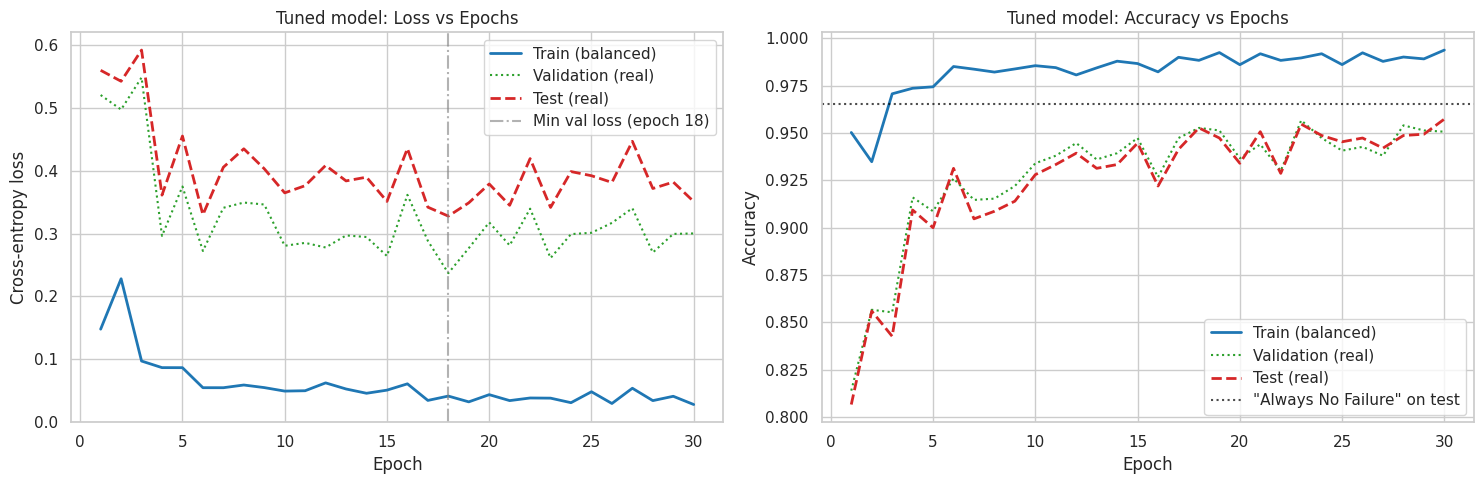

In [60]:
healthy = le.transform(['No Failure'])[0]
majority_acc_test = (y_test == healthy).mean()   # accuracy of "always say No Failure"
print(f"Majority-class accuracy on test: {majority_acc_test:.4f}")

def plot_history(hist, title):
    ep = np.arange(1, len(hist['train_loss']) + 1)
    best_ep = int(np.argmin(hist['val_loss'])) + 1   # chosen on VALIDATION, never on test

    fig, axes = plt.subplots(1, 2, figsize=(15, 5))

    # ---------- Loss vs epochs ----------
    ax = axes[0]
    ax.plot(ep, hist['train_loss'], color='tab:blue',  lw=2, label='Train (balanced)')
    ax.plot(ep, hist['val_loss'],   color='tab:green', lw=1.5, ls=':',  label='Validation (real)')
    ax.plot(ep, hist['test_loss'],  color='tab:red',   lw=2, ls='--', label='Test (real)')
    ax.axvline(best_ep, color='grey', ls='-.', alpha=0.6,
               label=f'Min val loss (epoch {best_ep})')
    ax.set_xlabel('Epoch'); ax.set_ylabel('Cross-entropy loss')
    ax.set_title(f'{title}: Loss vs Epochs')
    ax.legend()

    # ---------- Accuracy vs epochs ----------
    ax = axes[1]
    ax.plot(ep, hist['train_acc'], color='tab:blue',  lw=2, label='Train (balanced)')
    ax.plot(ep, hist['val_acc'],   color='tab:green', lw=1.5, ls=':',  label='Validation (real)')
    ax.plot(ep, hist['test_acc'],  color='tab:red',   lw=2, ls='--', label='Test (real)')
    ax.axhline(majority_acc_test, color='black', ls=':', alpha=0.7,
               label='"Always No Failure" on test')
    ax.set_xlabel('Epoch'); ax.set_ylabel('Accuracy')
    ax.set_title(f'{title}: Accuracy vs Epochs')
    ax.legend(loc='lower right')

    plt.tight_layout(); plt.show()

plot_history(hist_tuned, 'Tuned model')

**7.Metrics (accuracy, sensitivity, F1, confusion matrix)**

In [61]:
from sklearn.metrics import (precision_recall_fscore_support, classification_report,
                             confusion_matrix, accuracy_score, balanced_accuracy_score)

labels_order = le.transform(class_order)            # same class order as the EDA
short_names  = ['No Failure', 'Heat Diss.', 'Power', 'Overstrain', 'Tool Wear', 'Random']
healthy      = le.transform(['No Failure'])[0]

def predict_all(model, X, batch=2048):
    """Return predicted class ids for a NumPy array X."""
    model.eval()
    out = []
    with torch.no_grad():
        for i in range(0, len(X), batch):
            xb = torch.tensor(X[i:i + batch], dtype=torch.float32).to(device)
            out.append(model(xb).argmax(dim=1).cpu().numpy())
    return np.concatenate(out)

datasets = {
    'Train (balanced, SMOTE)': (X_train_res, y_train_res),
    'Train (real only)':       (X_train, y_train),
    'Validation (real)':      (X_val, y_val),
    'Test (real)':            (X_test, y_test),
}

In [62]:
def summary_row(y_true, y_pred):
    p, r, f, _ = precision_recall_fscore_support(
        y_true, y_pred, labels=labels_order, average='macro', zero_division=0)
    fw = precision_recall_fscore_support(
        y_true, y_pred, labels=labels_order, average='weighted', zero_division=0)[2]
    true_fail, pred_fail = (y_true != healthy), (y_pred != healthy)
    return {
        'accuracy':           accuracy_score(y_true, y_pred),
        'balanced_acc':       balanced_accuracy_score(y_true, y_pred),
        'macro_precision':    p,
        'macro_recall':       r,
        'macro_F1':           f,
        'weighted_F1':        fw,
        'failure_detection':  (pred_fail & true_fail).sum() / true_fail.sum(),
        'false_alarm_rate':   (pred_fail & ~true_fail).sum() / (~true_fail).sum(),
    }

rows, preds = {}, {}
for mname, model in [('Baseline', baseline), ('Tuned', tuned)]:
    for dname, (X_, y_) in datasets.items():
        yp = predict_all(model, X_)
        preds[(mname, dname)] = yp
        rows[(mname, dname)] = summary_row(y_, yp)

summary = pd.DataFrame(rows).T.round(4)
summary.index.names = ['model', 'set']
print(summary.to_string())

                                  accuracy  balanced_acc  macro_precision  macro_recall  macro_F1  weighted_F1  failure_detection  false_alarm_rate
model    set                                                                                                                                       
Baseline Train (balanced, SMOTE)    0.9923        0.9923           0.9924        0.9923    0.9923       0.9923             0.9997            0.0406
         Train (real only)          0.9595        0.9448           0.5965        0.9448    0.6760       0.9706             0.9631            0.0406
         Validation (real)          0.9440        0.6210           0.5131        0.6210    0.5582       0.9600             0.7885            0.0498
         Test (real)                0.9460        0.6018           0.4653        0.6018    0.5159       0.9599             0.8269            0.0456
Tuned    Train (balanced, SMOTE)    0.9938        0.9938           0.9938        0.9938    0.9937       0.9937  

In [63]:
def per_class_table(y_true, y_pred):
    cm = confusion_matrix(y_true, y_pred, labels=labels_order)
    tp = np.diag(cm); fn = cm.sum(1) - tp
    fp = cm.sum(0) - tp; tn = cm.sum() - tp - fn - fp
    return pd.DataFrame({
        'support':              cm.sum(1),
        'precision':            tp / np.maximum(tp + fp, 1),
        'recall (sensitivity)': tp / np.maximum(tp + fn, 1),
        'specificity':          tn / np.maximum(tn + fp, 1),
        'F1':                   2 * tp / np.maximum(2 * tp + fp + fn, 1),
    }, index=class_order).round(3)

for dname in ['Train (real only)', 'Test (real)']:
    y_ = datasets[dname][1]
    print(f"\n=== Tuned model, {dname} ===")
    print(per_class_table(y_, preds[('Tuned', dname)]).to_string())

# Same thing in the standard sklearn format, for the test set
print("\n", classification_report(y_test, preds[('Tuned', 'Test (real)')],
      labels=labels_order, target_names=class_order, digits=3, zero_division=0))


=== Tuned model, Train (real only) ===
                          support  precision  recall (sensitivity)  specificity     F1
No Failure                   6749      0.999                 0.968        0.963  0.983
Heat Dissipation Failure       78      0.934                 0.910        0.999  0.922
Power Failure                  66      0.802                 0.985        0.998  0.884
Overstrain Failure             55      0.786                 1.000        0.998  0.880
Tool Wear Failure              32      0.254                 0.969        0.987  0.403
Random Failures                13      0.127                 1.000        0.987  0.226

=== Tuned model, Test (real) ===
                          support  precision  recall (sensitivity)  specificity     F1
No Failure                   1447      0.989                 0.969        0.712  0.979
Heat Dissipation Failure       17      0.882                 0.882        0.999  0.882
Power Failure                  14      0.500            

**8 .Regularization and comparison with the first model**

In [64]:
import copy

class NetReg(nn.Module):
    """Same architecture as Net, with optional BatchNorm and Dropout.
    Block order: Linear -> BatchNorm -> ReLU -> Dropout."""
    def __init__(self, n_in=6, hidden=(64, 32), n_out=6, dropout=0.0, batchnorm=False):
        super().__init__()
        layers, prev = [], n_in
        for h in hidden:
            layers.append(nn.Linear(prev, h))
            if batchnorm:
                layers.append(nn.BatchNorm1d(h))
            layers.append(nn.ReLU())
            if dropout > 0:
                layers.append(nn.Dropout(dropout))
            prev = h
        layers.append(nn.Linear(prev, n_out))
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x)


def train_model_reg(model, epochs, lr, opt_cls, opt_kwargs=None,
                    weight_decay=0.0, patience=None):
    criterion = nn.CrossEntropyLoss()
    kw = dict(opt_kwargs or {})
    if weight_decay > 0:
        kw['weight_decay'] = weight_decay                 # L2 regularization
    optimizer = opt_cls(model.parameters(), lr=lr, **kw)

    hist = {k: [] for k in ['train_loss', 'train_acc', 'val_loss',
                            'val_acc', 'test_loss', 'test_acc']}
    best_val, best_state, best_epoch, wait = float('inf'), None, 0, 0

    for epoch in range(1, epochs + 1):
        model.train()                                     # dropout/batchnorm ON
        for xb, yb in train_loader:
            xb, yb = xb.to(device), yb.to(device)
            optimizer.zero_grad()
            criterion(model(xb), yb).backward()
            optimizer.step()

        for name, loader in [('train', train_eval_loader),
                             ('val', val_loader), ('test', test_loader)]:
            l, a = evaluate(model, loader, criterion)     # evaluate() uses model.eval()
            hist[f'{name}_loss'].append(l)
            hist[f'{name}_acc'].append(a)

        if patience:                                      # early stopping on VALIDATION loss
            if hist['val_loss'][-1] < best_val - 1e-4:
                best_val, best_epoch, wait = hist['val_loss'][-1], epoch, 0
                best_state = copy.deepcopy(model.state_dict())
            else:
                wait += 1
                if wait >= patience:
                    break

    if patience and best_state is not None:
        model.load_state_dict(best_state)                 # go back to the best epoch
    hist['best_epoch'] = best_epoch if patience else epochs
    hist['stopped_epoch'] = epoch
    return hist

In [65]:
configs = {
    'L2 (wd=1e-3)':             dict(dropout=0.0, bn=False, wd=1e-3, pat=None),
    'Dropout (p=0.3)':          dict(dropout=0.3, bn=False, wd=0.0,  pat=None),
    'BatchNorm':                dict(dropout=0.0, bn=True,  wd=0.0,  pat=None),
    'Early stopping (pat=10)':  dict(dropout=0.0, bn=False, wd=0.0,  pat=10),
    'Dropout+L2+EarlyStop':     dict(dropout=0.3, bn=False, wd=1e-3, pat=10),
}

models = {'Model 1 (no reg.)': tuned}
hists  = {'Model 1 (no reg.)': hist_tuned}

for name, c in configs.items():
    torch.manual_seed(42)
    m = NetReg(hidden=hidden, dropout=c['dropout'], batchnorm=c['bn']).to(device)
    hists[name] = train_model_reg(m, epochs=epochs, lr=lr, opt_cls=opt_cls,
                                  opt_kwargs=opt_kwargs,
                                  weight_decay=c['wd'], patience=c['pat'])
    models[name] = m
    print(f"{name:26s} stopped at epoch {hists[name]['stopped_epoch']:3d}, "
          f"best epoch {hists[name]['best_epoch']}")

L2 (wd=1e-3)               stopped at epoch  30, best epoch 30
Dropout (p=0.3)            stopped at epoch  30, best epoch 30
BatchNorm                  stopped at epoch  30, best epoch 30
Early stopping (pat=10)    stopped at epoch  28, best epoch 18
Dropout+L2+EarlyStop       stopped at epoch  21, best epoch 11


In [66]:
rows = []
for name, m in models.items():
    r_te = summary_row(y_test,  predict_all(m, X_test))
    r_va = summary_row(y_val,   predict_all(m, X_val))
    r_tr = summary_row(y_train, predict_all(m, X_train))      # real training rows
    rows.append({
        'model': name,
        'val_macro_F1':     r_va['macro_F1'],
        'train_macro_F1':   r_tr['macro_F1'],
        'test_macro_F1':    r_te['macro_F1'],
        'train-test gap':   r_tr['macro_F1'] - r_te['macro_F1'],
        'test_accuracy':    r_te['accuracy'],
        'test_bal_acc':     r_te['balanced_acc'],
        'failure_detect.':  r_te['failure_detection'],
        'false_alarm':      r_te['false_alarm_rate'],
        'final_test_loss':  hists[name]['test_loss'][-1],
    })
comp = pd.DataFrame(rows).set_index('model').round(4)
print(comp.to_string())

best_name = comp['val_macro_F1'].idxmax()          # chosen on VALIDATION only
print("\nBest model according to validation macro F1:", best_name)

                         val_macro_F1  train_macro_F1  test_macro_F1  train-test gap  test_accuracy  test_bal_acc  failure_detect.  false_alarm  final_test_loss
model                                                                                                                                                           
Model 1 (no reg.)              0.5744          0.7164         0.5304          0.1860         0.9573        0.5585           0.7115       0.0311           0.3511
L2 (wd=1e-3)                   0.5437          0.5397         0.4892          0.0505         0.8773        0.6155           0.8462       0.1182           0.3639
Dropout (p=0.3)                0.5274          0.5273         0.4820          0.0452         0.8806        0.6749           0.8846       0.1175           0.4640
BatchNorm                      0.5816          0.6417         0.5213          0.1204         0.9113        0.6034           0.8077       0.0822           0.3322
Early stopping (pat=10)        0.5